# ⏱️ Pocket Clock — how much time does the QB really have?
NFL **2021** weeks 1-8 (Big Data Bowl 2023). Invented metric: **Clean Pocket Time (CPT)** = seconds between the snap and the first moment a pass rusher gets within 2 yd of the QB. If nobody arrives before the throw/sack, the play is *censored* (kept, handled with Kaplan-Meier).

In [1]:
import os, sys; os.chdir(os.path.dirname(os.path.abspath('')) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()); sys.path.insert(0, os.getcwd())
import pandas as pd; from IPython.display import Image, display
from src import load, metrics, analysis as A, validate, viz
# DEBUG=1 in the environment -> 5 games only

## 1. Loading (parquet cache) and CPT

In [2]:
t = load.load_all(); load.summary(t)
tab, duels, sk = metrics.build_table(t); metrics.summary(tab, sk)
tab.head()

[load] mode=FULL | games=122 | plays.csv plays=8557 | tracked plays (with snap)=8533 | skipped (no snap)=24 | tracking rows=6,327,553


[cpt] radius=2.0 yd | plays=8532 (skipped: 25) | median CPT=2.60s | censored=67.9% | CPT=0: 0.4%


,gameId,playId,duration,first_rusherId,cpt,first_entry_speed,censored,cpt_1.5,cpt_2.0,cpt_3.0,...,quarter,n_rushers,n_blockers,qbId,pff_pressure,first_rusher,qb,first_blockerId,first_blocker,first_blocker_pos
0,2021090900,97,3.2,NaN,3.2,NaN,True,3.2,3.2,2.6,...,1,5,5,25511,True,NaN,Tom Brady,NaN,NaN,NaN
1,2021090900,137,2.6,NaN,2.6,NaN,True,2.6,2.6,2.4,...,1,5,5,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
2,2021090900,187,2.0,NaN,2.0,NaN,True,2.0,2.0,2.0,...,1,4,5,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
3,2021090900,282,3.2,NaN,3.2,NaN,True,3.2,3.2,0.0,...,1,5,7,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
4,2021090900,349,2.6,38588.0,2.2,3.98,False,2.6,2.2,1.8,...,1,5,6,43424,True,Lavonte David,Dak Prescott,43293.0,Ezekiel Elliott,HB-L


## 2. Football validation
The CPT should be shorter on sacks, with more rushers, and agree with PFF pressures.

In [3]:
res = validate.run(tab)


== by_result ==
  result     n  RMST_3s  clean_2.5s  censored  median_throw_t
0      C  4604    2.860       0.886     0.792             2.6
1      I  2750    2.836       0.853     0.657             2.9
2     IN   189    2.871       0.889     0.646             3.1
3      R   447    2.793       0.834     0.459             4.2
4      S   542    2.629       0.616     0.028             4.3

== by_blitz ==
         blitz     n  RMST_3s  clean_2.5s  censored  median_throw_t
0  3-4 rushers  6428    2.852       0.871     0.692             2.9
1    5 rushers  1686    2.762       0.793     0.639             2.7
2   6+ rushers   418    2.673       0.705     0.646             2.5

== by_play_action ==
   pff_playAction     n  RMST_3s  clean_2.5s  censored  median_throw_t
0               0  6497    2.823       0.828     0.675             2.7
1               1  2035    2.815       0.894     0.694             3.3

== by_coverage ==
  pff_passCoverageType     n  RMST_3s  clean_2.5s  censored  median_t

## 3. Visualizations

In [4]:
viz.make_all(t, tab, duels)

  -> 01_offensive_line_ranking.png


  -> 02_pass_rush_team_ranking.png


  -> 03_top_pass_rushers.png


  -> 04_pocket_clock_by_rushers.png


  -> 05_pocket_clock_man_vs_zone.png


  -> 06_cpt_over_expected.png


  -> 07_qb_internal_clock.png


  robustness spearman:
         1.5 yd  2.0 yd  3.0 yd
1.5 yd    1.00    0.73    0.47
2.0 yd    0.73    1.00    0.45
3.0 yd    0.47    0.45    1.00


  -> 08_fastest_sack.gif
  GIF : NE-NYJ, CPT=0.9s, rusher=Del'Shawn Phillips


{'ol':    team    n      rmst  clean_2.5s  sack_rate  rank
 0    LA  249  2.954500    0.951458   0.032129     1
 1   CLE  249  2.913739    0.930014   0.092369     2
 2   ARI  233  2.912818    0.933581   0.085837     3
 3   WAS  298  2.898909    0.941780   0.050336     4
 4   BUF  253  2.894945    0.898456   0.027668     5
 5    TB  309  2.893533    0.893053   0.038835     6
 6   BAL  271  2.891298    0.888380   0.081181     7
 7    GB  226  2.879572    0.897251   0.075221     8
 8   PHI  254  2.877370    0.874743   0.051181     9
 9   SEA  230  2.857658    0.852966   0.108696    10
 10   NO  203  2.856396    0.888351   0.059113    11
 11   KC  338  2.852896    0.881732   0.044379    12
 12  NYJ  269  2.841812    0.889530   0.078067    13
 13  CAR  294  2.841198    0.834849   0.078231    14
 14  DAL  261  2.828984    0.823523   0.045977    15
 15  CIN  258  2.818275    0.837257   0.077519    16
 16   SF  216  2.816364    0.867119   0.050926    17
 17  CHI  247  2.815966    0.817446   0.

### Offensive lines

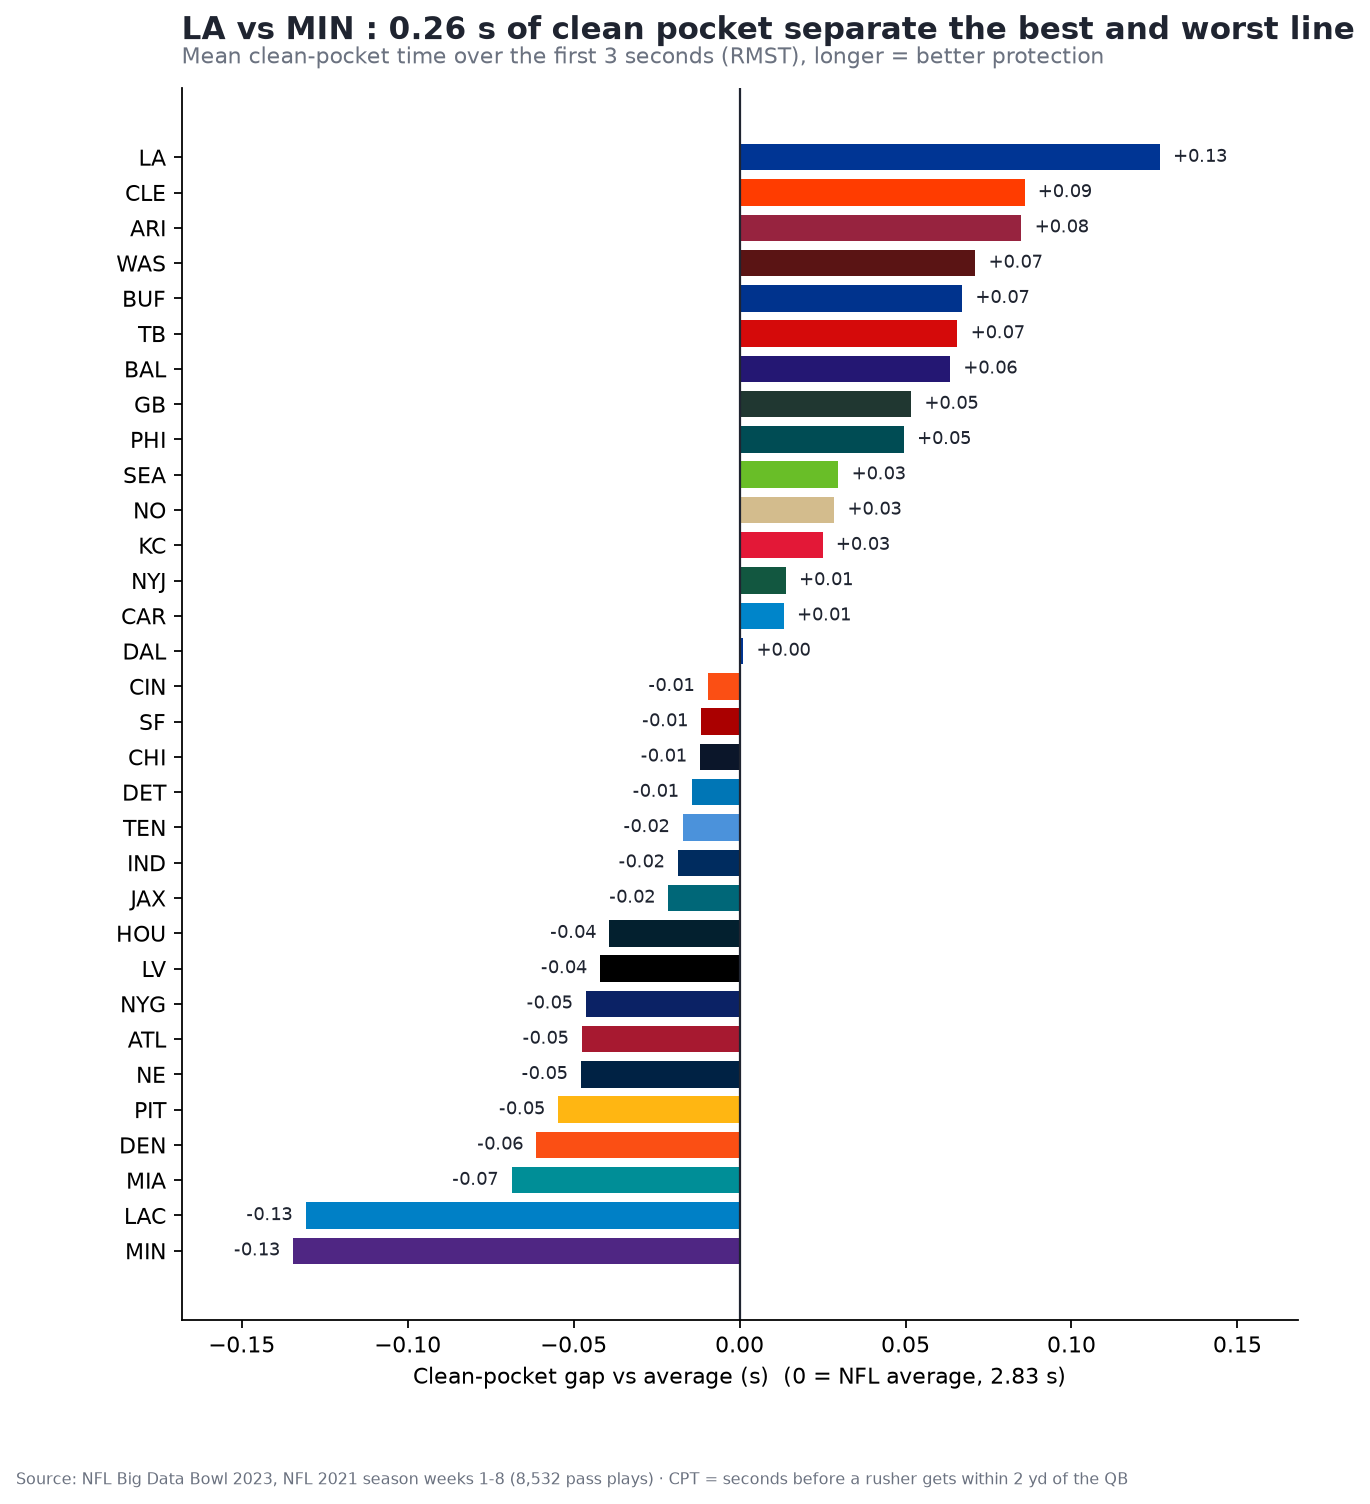

In [5]:
display(Image('outputs/01_offensive_line_ranking.png'))

### Pass rush by team

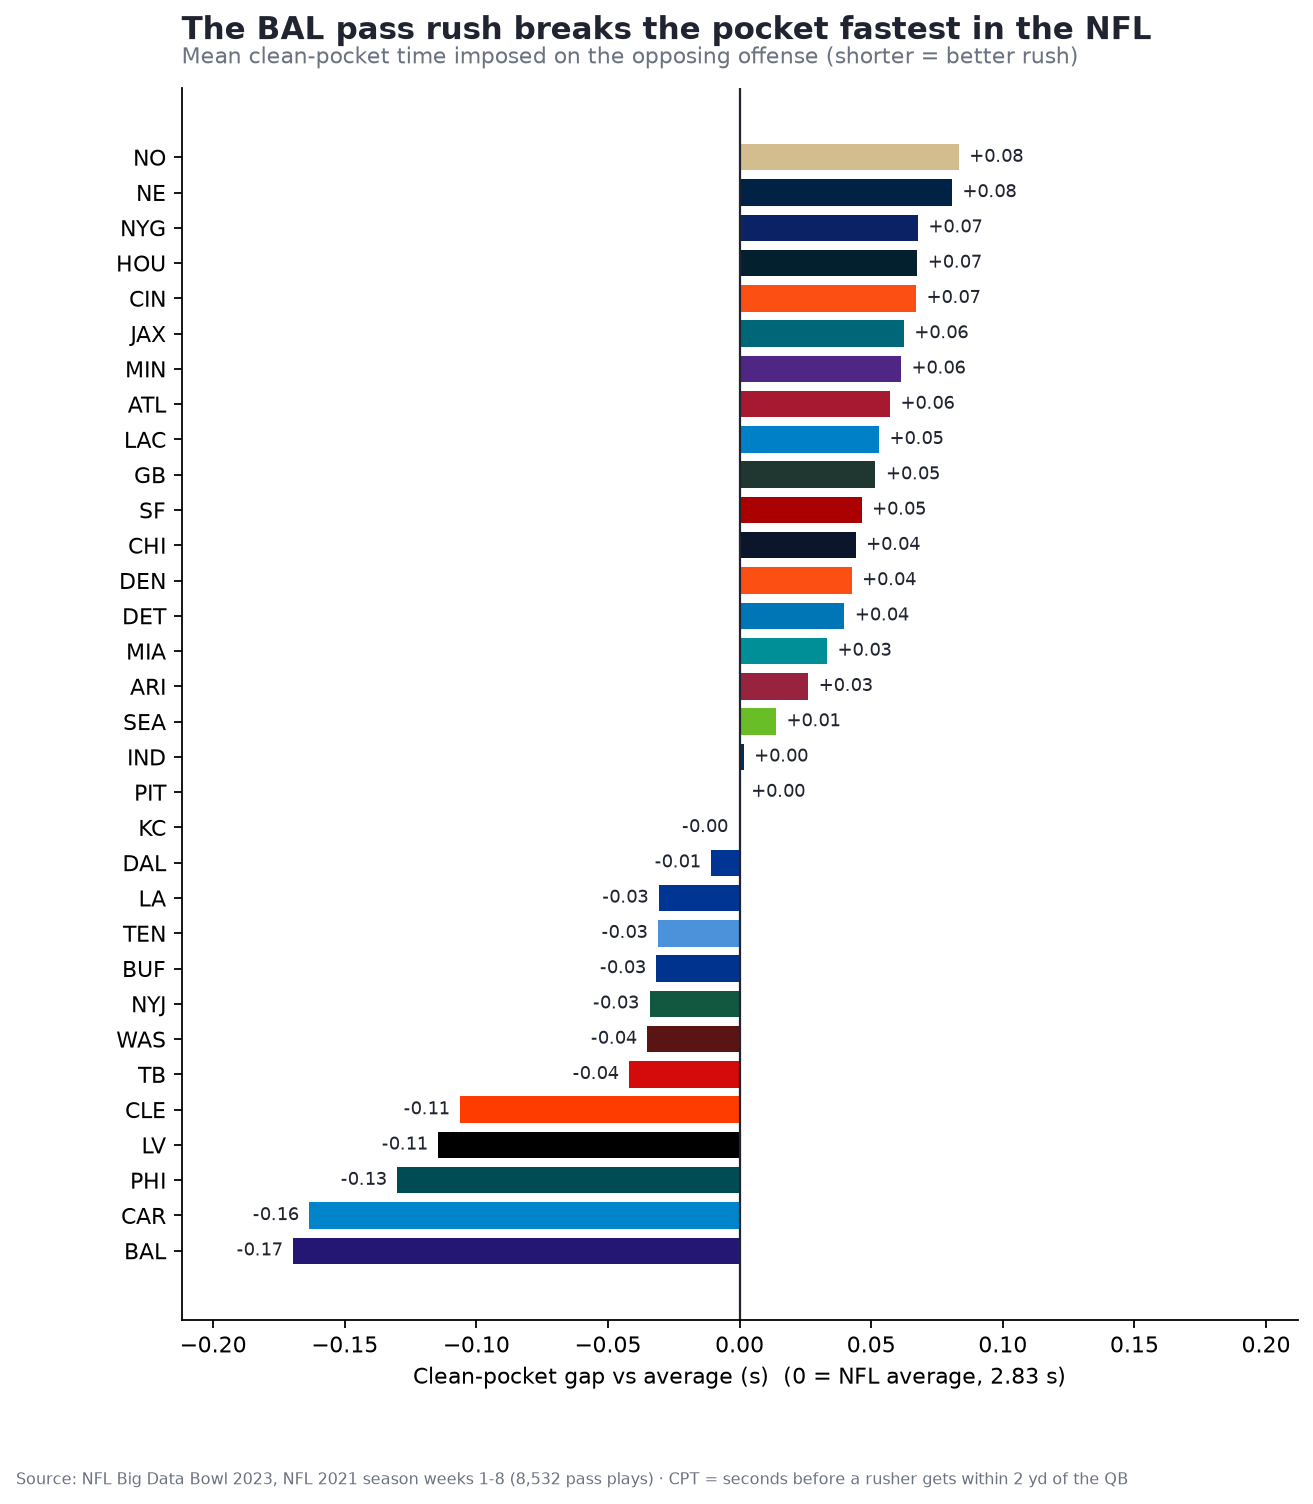

In [6]:
display(Image('outputs/02_pass_rush_team_ranking.png'))

### Best rushers

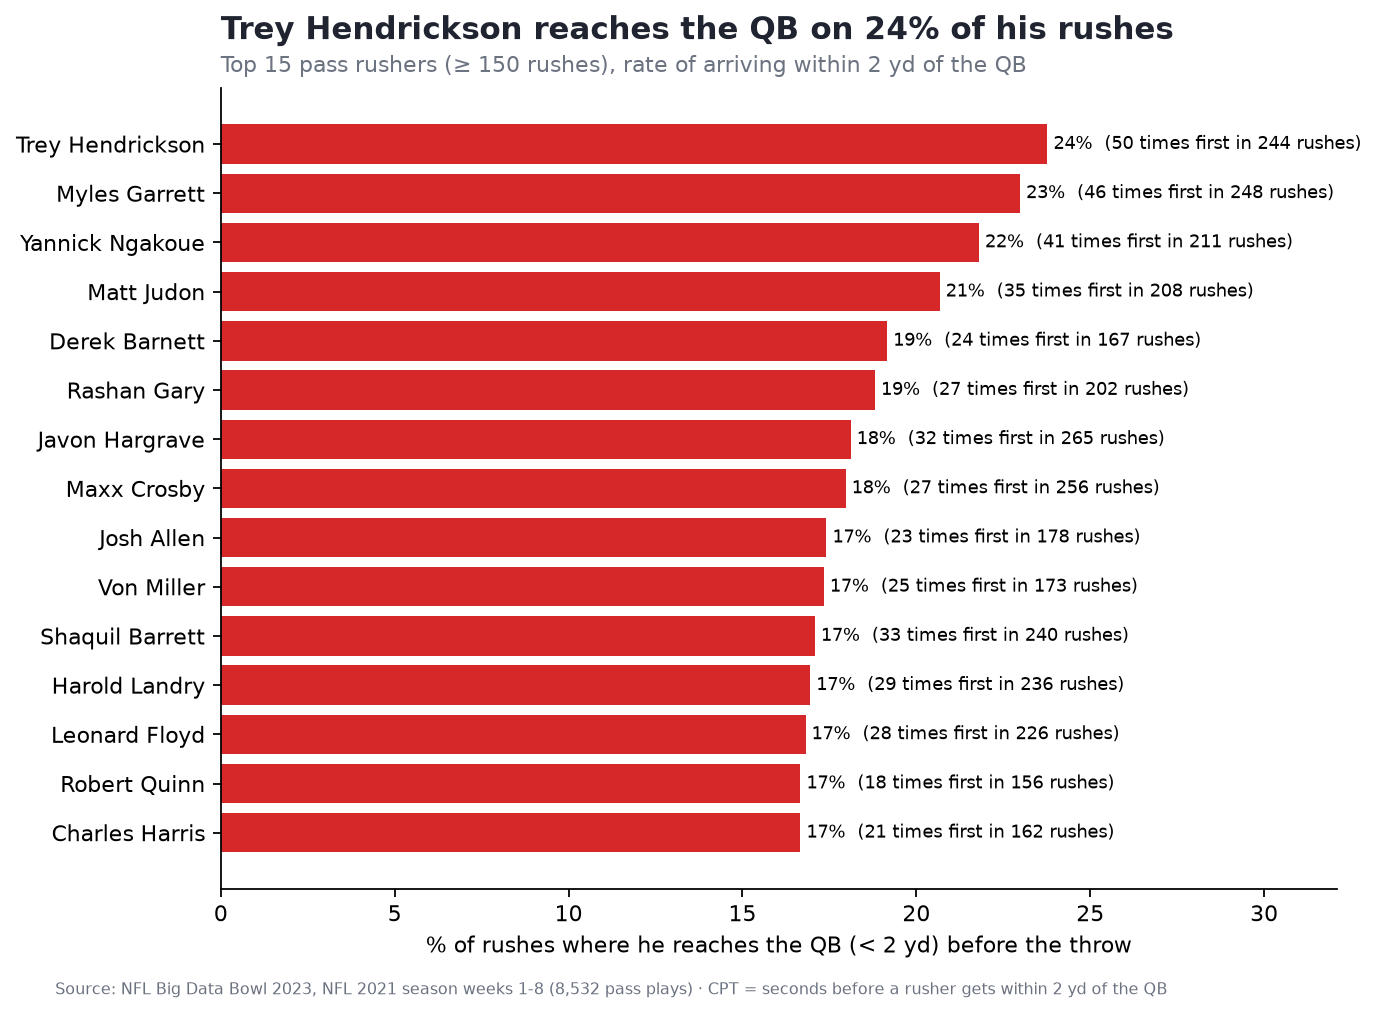

In [7]:
display(Image('outputs/03_top_pass_rushers.png'))

### Pocket clock

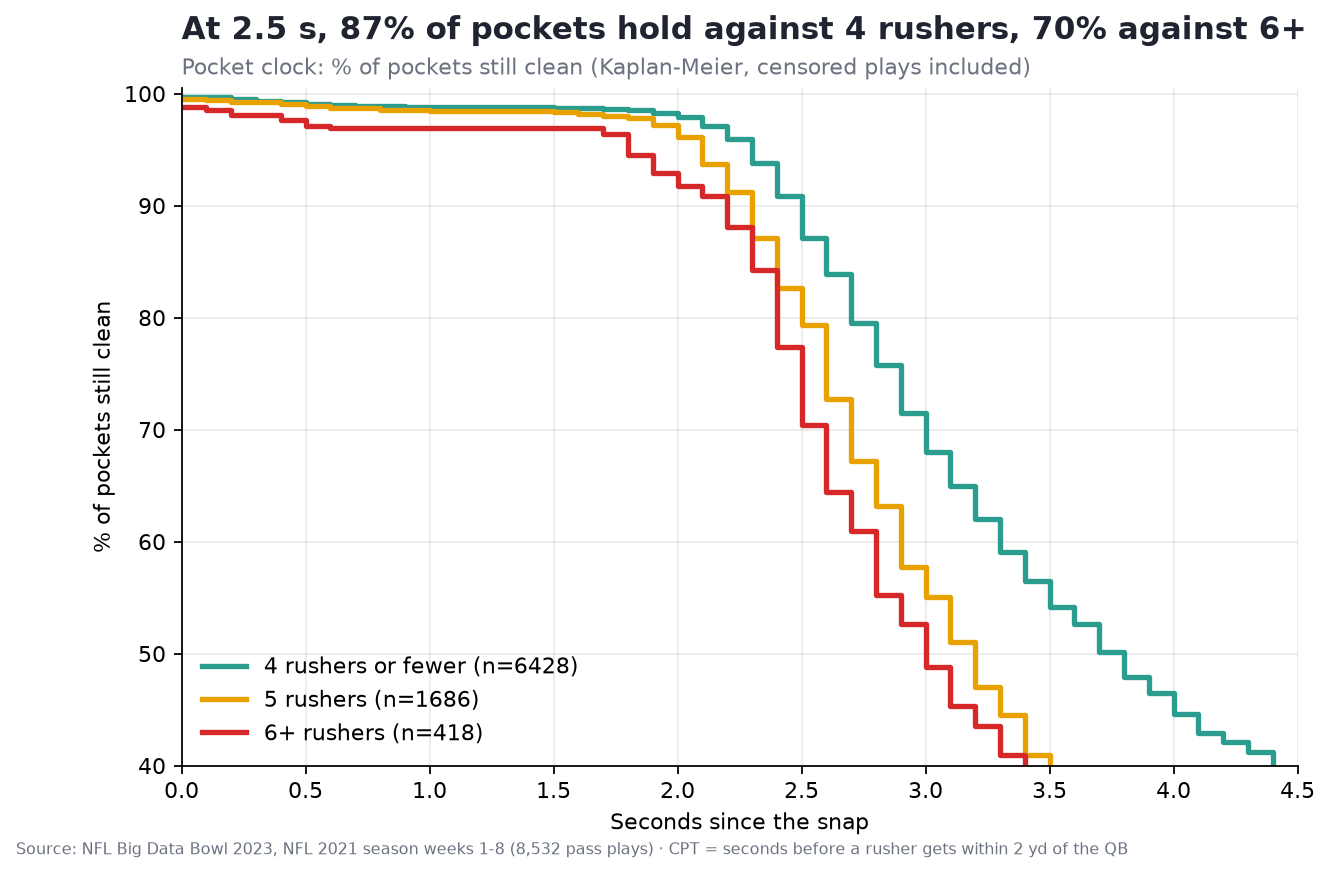

In [8]:
display(Image('outputs/04_pocket_clock_by_rushers.png'))

### CPT over expected

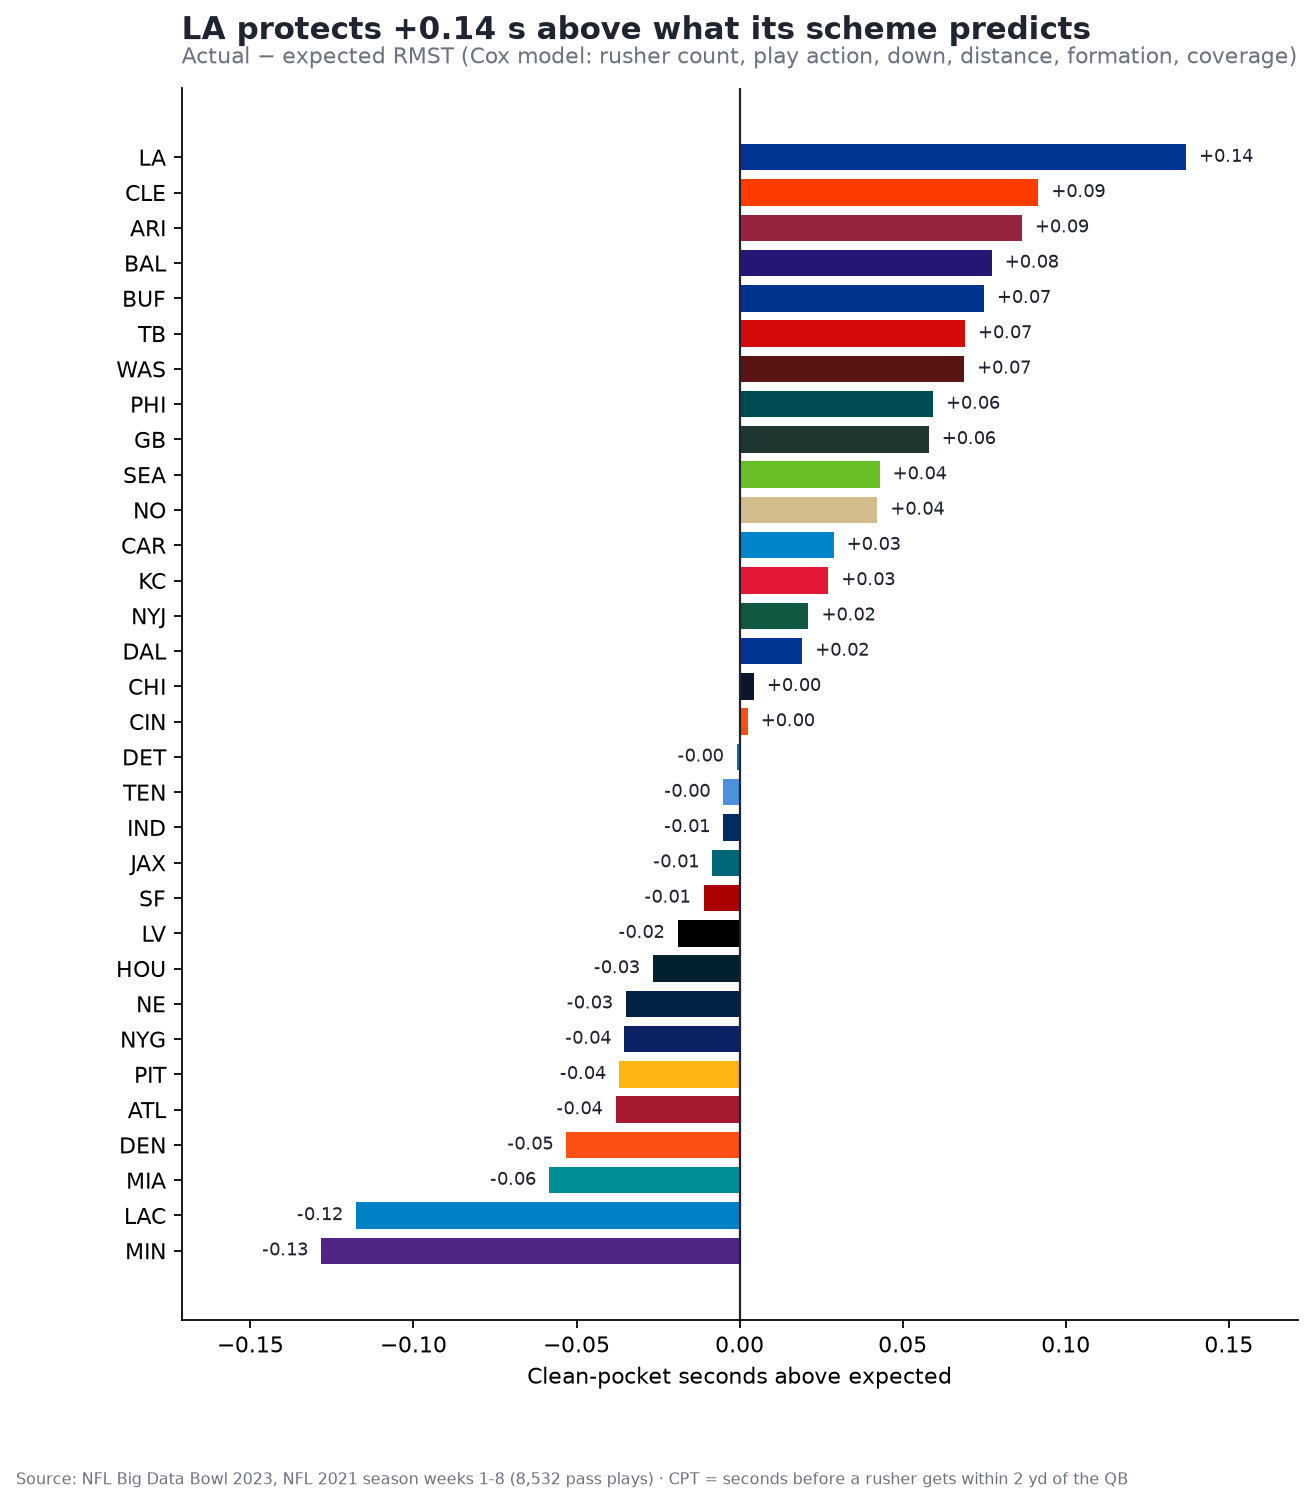

In [9]:
display(Image('outputs/06_cpt_over_expected.png'))

### QB: internal clock

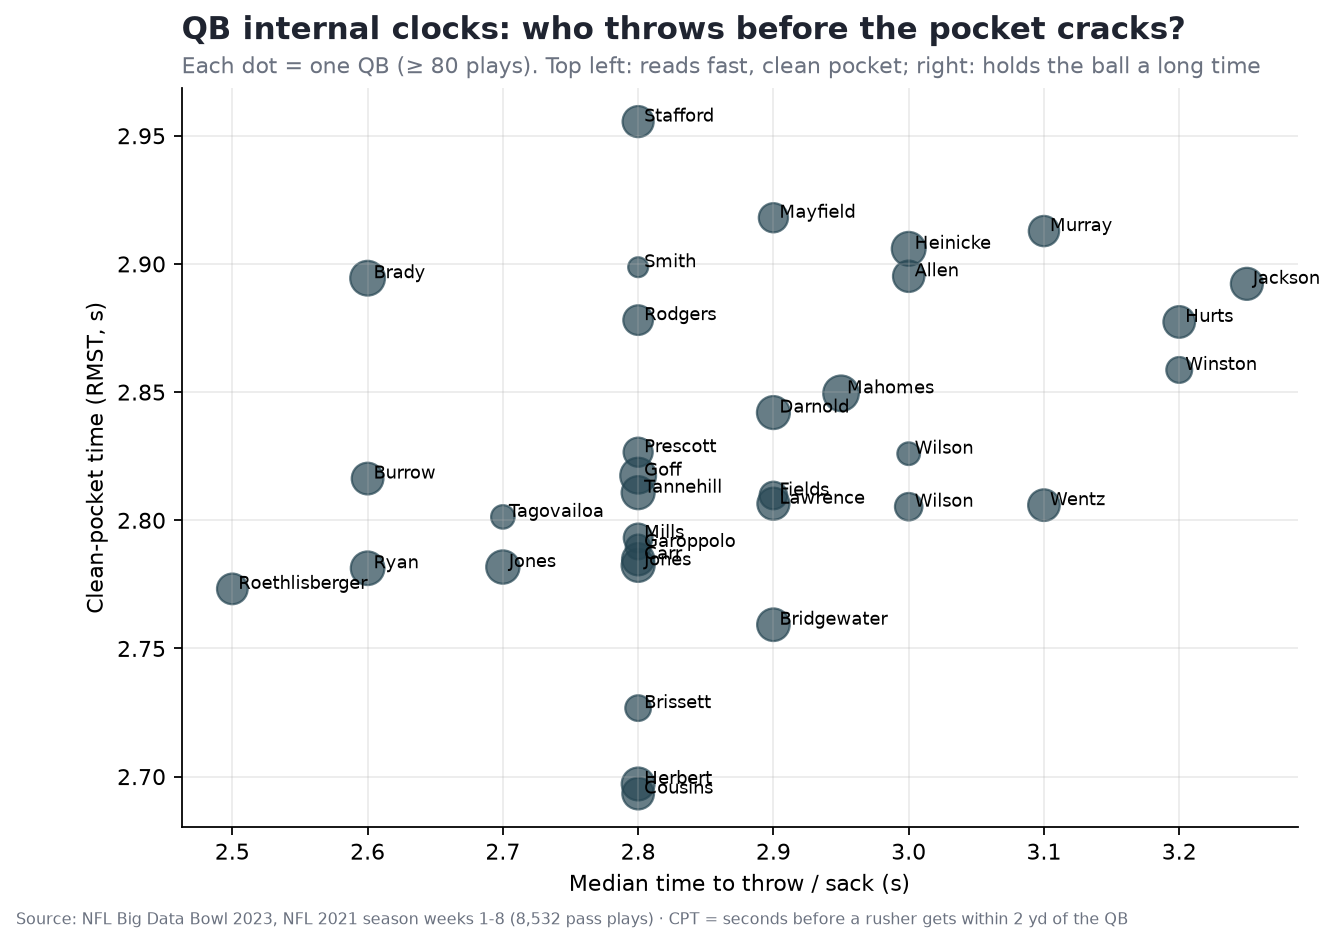

In [10]:
display(Image('outputs/07_qb_internal_clock.png'))

### The fastest sack (GIF)

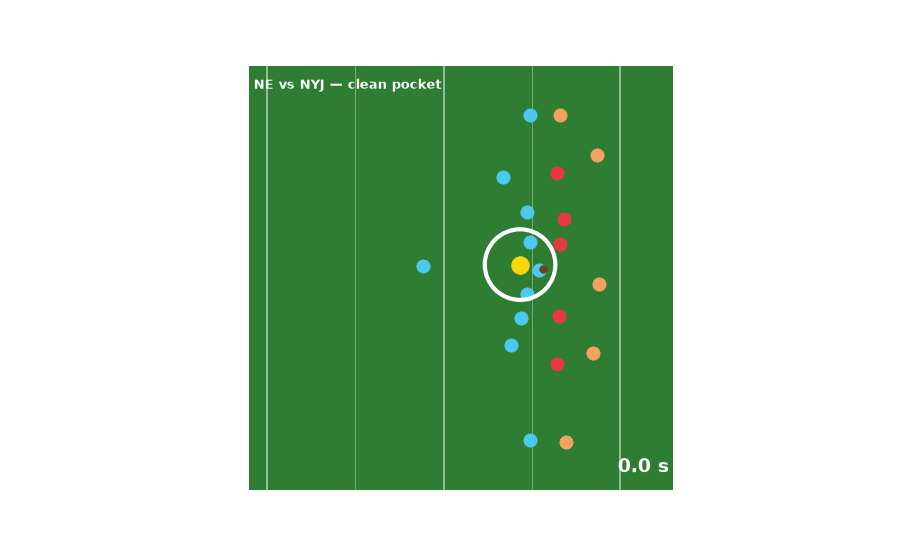

In [11]:
display(Image('outputs/08_fastest_sack.gif'))

## 4. Threshold robustness (1.5 / 2 / 3 yd)

In [12]:
rob = pd.read_csv('outputs/robustness_ol_ranking.csv', index_col=0); display(rob.corr(method='spearman').round(2)); rob

,1.5 yd,2.0 yd,3.0 yd
1.5 yd,1.00,0.73,0.47
2.0 yd,0.73,1.00,0.45
3.0 yd,0.47,0.45,1.00


,1.5 yd,2.0 yd,3.0 yd
team,,,
LA,1,1,8
CLE,6,2,21
ARI,4,3,1
WAS,2,4,5
BUF,10,5,6
TB,3,6,15
BAL,8,7,2
GB,9,8,18
PHI,18,9,3


## Limitations
Only 8 weeks (~250 plays/team), arbitrary 2 yd threshold (moderately stable rankings: Spearman ρ ≈ 0.45-0.73 across thresholds), ~68% of plays censored (the QB throws before pressure) → curves unreliable beyond ~3 s, and distance captures neither blocking quality nor the QB's reads.